# ML-I Lab Project: P59 – Heart Failure Survival Prediction
**Predicting In-Hospital and Post-Discharge Survival from Clinical Records Using Logistic Regression**

### Student Information:
- **Student Name:** NUPUR THAKER
- **Roll Number:** B55
- **Division:** Div D
- **Enrollment Number:** 24004501210444
- **Project ID:** P59
- **Problem Type:** Binary Classification
- **Assigned Model:** Logistic Regression
- **Primary Optimization Metrics:** Recall (Sensitivity) and ROC-AUC

---
### Clinical Problem Statement
Heart failure (HF) occurs when the heart myocardium cannot pump sufficient blood to meet the metabolic demands of the body. It is a leading cause of cardiovascular mortality globally. Accurate identification of high-risk patients enables emergency triage, aggressive medication adjustment, and intensive monitoring. In clinical triage, **Recall** is far more critical than raw Accuracy: a **False Negative** (failing to identify a patient at risk of death) can result in avoidable mortality, whereas a **False Positive** results in benign additional surveillance.

## Step 1: Create your notebook and load the libraries
We import essential data science, visualization, and machine learning libraries including `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scikit-learn`.

In [1]:
import os
os.environ['MPLCONFIGDIR'] = os.path.join(os.environ.get('TEMP', '.'), 'matplotlib')

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay, roc_curve
)

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully!")

All libraries loaded successfully!


## Step 2: Load your dataset
We load `heart_failure_clinical_records_dataset.csv`.
- **Dataset Source:** Kaggle / UCI Machine Learning Repository (Davide Chicco & Giuseppe Jurman, *BMC Medical Informatics and Decision Making*, 2020).
- **Target Variable:** `DEATH_EVENT` (0 = Survived, 1 = Deceased).

In [2]:
df = pd.read_csv("heart_failure_clinical_records_dataset.csv")
print("Dataset Shape (Rows, Columns):", df.shape)
df.head()

Dataset Shape (Rows, Columns): (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## Step 3: Understand the data
We inspect the structural schema, data types, missing values, duplicates, and formulate the comprehensive clinical data dictionary.

### Clinical Data Dictionary Table
| Column Name | Clinical Meaning | Clinical Unit | Type | Role & Action |
| :--- | :--- | :--- | :--- | :--- |
| **age** | Age of the patient | Years | Numeric (Int) | Keep (Major independent risk factor) |
| **anaemia** | Decrease of red blood cells / hemoglobin | 0: No, 1: Yes | Binary | Keep (Common HF comorbidity) |
| **creatinine_phosphokinase** | Level of the CPK enzyme in blood | mcg/L | Numeric (Int) | Keep (Marker of myocardial damage) |
| **diabetes** | Patient has diabetes mellitus | 0: No, 1: Yes | Binary | Keep (Cardiometabolic risk factor) |
| **ejection_fraction** | Percentage of blood leaving heart at each contraction | % | Numeric (Int) | Keep (Core systolic function marker) |
| **high_blood_pressure** | Patient has chronic hypertension | 0: No, 1: Yes | Binary | Keep (Vascular stress factor) |
| **platelets** | Blood platelet count | platelets/mL | Numeric (Float) | Keep (Coagulation / hematologic index) |
| **serum_creatinine** | Level of creatinine in blood | mg/dL | Numeric (Float) | Keep (Crucial renal function biomarker) |
| **serum_sodium** | Level of sodium in blood | mEq/L | Numeric (Int) | Keep (Electrolyte / fluid balance marker) |
| **sex** | Patient gender | 0: Female, 1: Male | Binary | Keep (Demographic variable) |
| **smoking** | Whether the patient smokes | 0: No, 1: Yes | Binary | Keep (Cardiovascular lifestyle factor) |
| **time** | Follow-up observation duration | Days | Numeric (Int) | **Drop (Target Leakage - see Step 5)** |
| **DEATH_EVENT** | Target: Mortality during follow-up | 0: Survived, 1: Deceased | Binary | **Target Variable (Y)** |

*Observations from Initial Data Exploration:*
1. The dataset contains 299 patient records with 0 missing values and 0 duplicate rows.
2. The physiological parameters align with clinical cardiology cohorts: ejection fraction has a median of 38% (indicating significant systolic dysfunction in this cohort, as normal is >50%), and serum creatinine has a median of 1.1 mg/dL.

In [3]:
print("--- Column Summary & Data Types ---")
df.info()

print("\n--- Summary Statistics of Numeric Attributes ---")
display(df.describe().T.round(2))

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows Count ---")
print("Duplicates:", df.duplicated().sum())

--- Column Summary & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 3

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0



--- Missing Values Check ---
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

--- Duplicate Rows Count ---
Duplicates: 0


## Step 4: Prepare the target column (Y)
The target column is `DEATH_EVENT`. We inspect class frequencies and evaluate the degree of class imbalance.

In [4]:
TARGET = "DEATH_EVENT"
print("Target Class Frequencies:")
print(df[TARGET].value_counts())

print("\nTarget Class Proportions:")
print(df[TARGET].value_counts(normalize=True).round(4))

Target Class Frequencies:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

Target Class Proportions:
DEATH_EVENT
0    0.6789
1    0.3211
Name: proportion, dtype: float64


*Target Imbalance Analysis:*
- **Survived (Class 0):** 203 patients (67.89%)
- **Deceased (Class 1):** 96 patients (32.11%)
- **Imbalance Ratio:** Approximately **2.11 : 1**.
- **Impact on Evaluation:** The dataset is moderately imbalanced. A trivial model predicting "0" (Survived) for all patients achieves **67.89% accuracy** while failing to catch even a single mortality event (0% Recall). Therefore, **Recall** and **ROC-AUC** are our primary decision metrics.

## Step 5: Clean the data & Prevent Clinical Target Leakage
### Special Methodological Note: The `time` Feature and Target Leakage
- `time` represents the number of follow-up days before the patient either died or exited the study.
- Patients who died often experienced fatal events early in their hospital stay or shortly after discharge (e.g. 4 to 30 days), whereas surviving patients remained under surveillance for up to 285 days.
- In prospective clinical deployment, when an acute heart failure patient enters the emergency department today, **their future follow-up duration is completely unknown**.
- Using `time` as an input feature gives away the answer (**post-hoc survivorship bias / target leakage**).
- Therefore, we drop `time` from our prospective clinical model. We also retain a copy with `time` to empirically demonstrate this leakage phenomenon in Step 10!

In [5]:
# 1) Deduplication safeguard
df = df.drop_duplicates()

# 2) Retain a dataset copy containing 'time' for the leakage experiment
df_with_time = df.copy()

# 3) Robust imputation pipeline for numeric and categorical columns
for col in df.columns:
    if col == TARGET:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

df = df.dropna(subset=[TARGET])

# 4) Drop 'time' feature to prevent clinical target leakage
df_clean = df.drop(columns=["time"])

print("Missing values left:", df_clean.isnull().sum().sum())
print("Prospective Dataset Shape:", df_clean.shape)

Missing values left: 0
Prospective Dataset Shape: (299, 12)


## Step 6: Explore the data with charts (EDA)
We conduct exploratory data visualization to uncover physiological relationships and distributions.

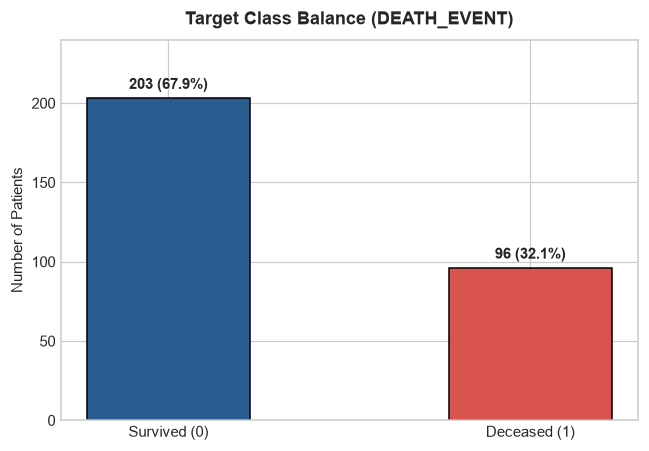

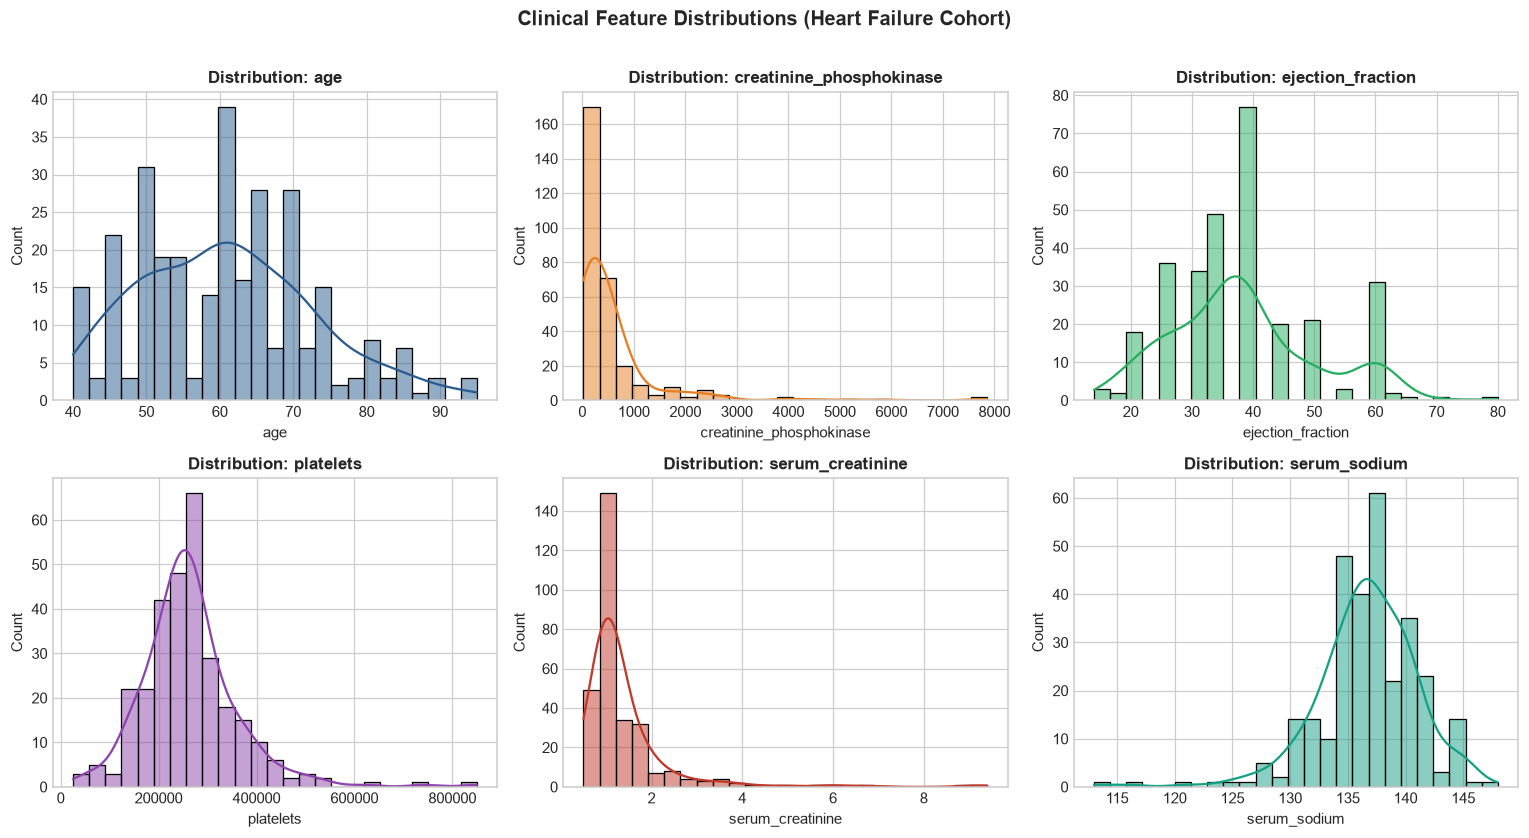

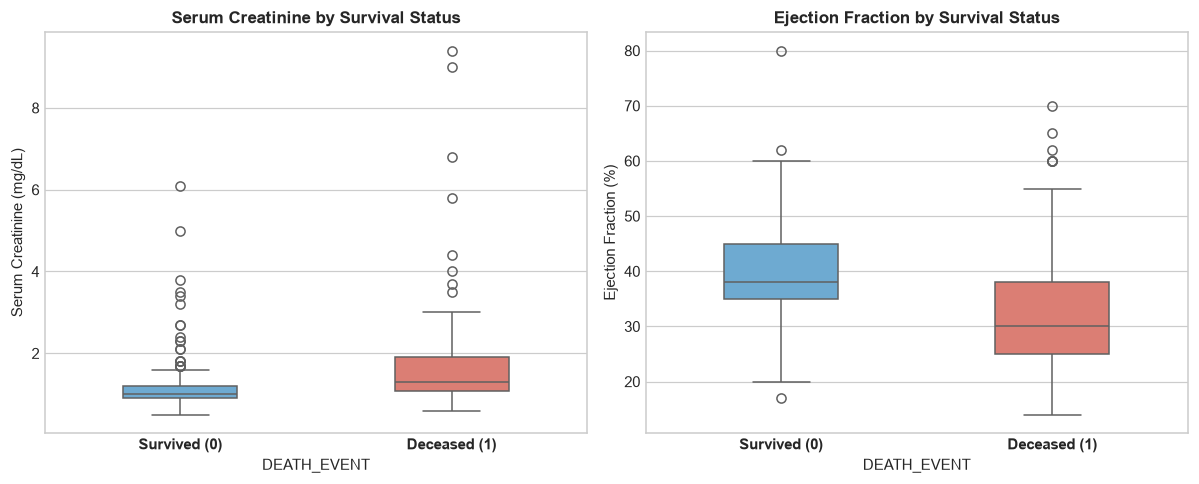

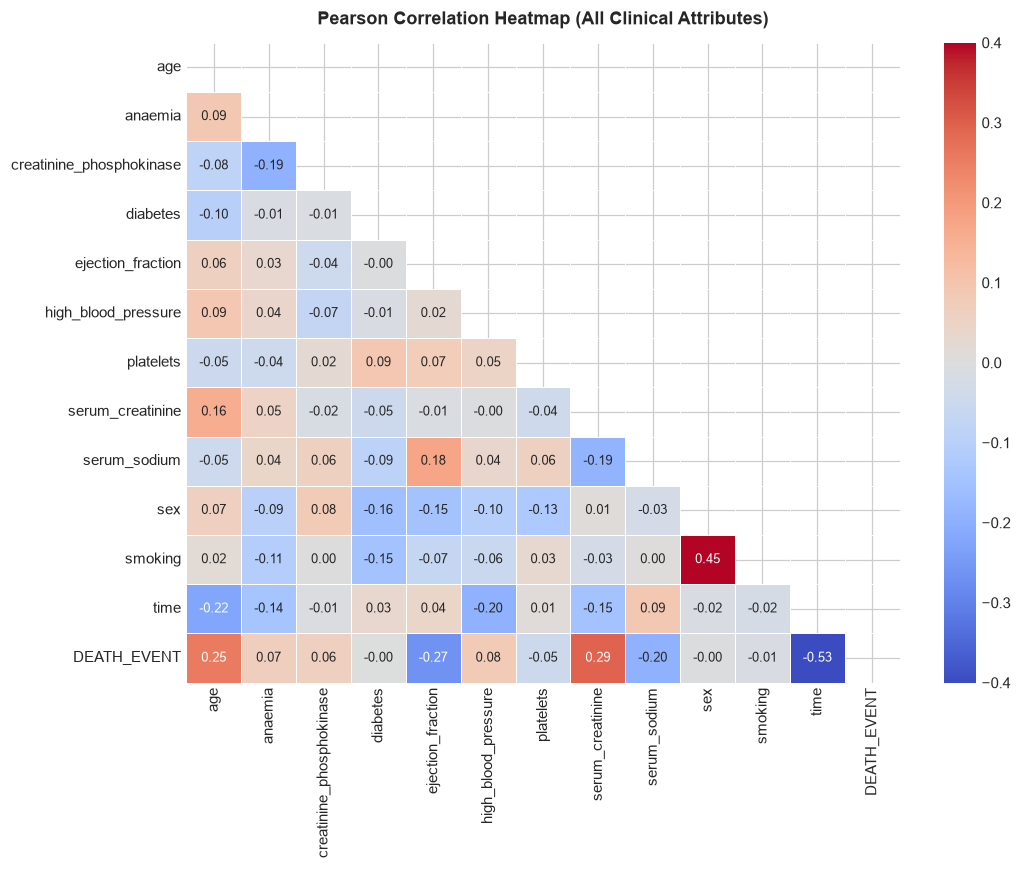

In [6]:
# Chart 1: Class Balance Countplot
fig, ax = plt.subplots(figsize=(6, 4.2))
counts = df[TARGET].value_counts()
bars = ax.bar(["Survived (0)", "Deceased (1)"], [counts[0], counts[1]], color=['#2b5c8f', '#d9534f'], width=0.45, edgecolor='black')
ax.set_title("Target Class Balance (DEATH_EVENT)", fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel("Number of Patients")
ax.set_ylim(0, 240)
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 4, f"{int(yval)} ({pct:.1f}%)", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.show()

# Chart 2: Feature Distributions
num_features = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium']
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
axes = axes.flatten()
colors = ['#2b5c8f', '#e67e22', '#27ae60', '#8e44ad', '#c0392b', '#16a085']
for idx, col in enumerate(num_features):
    sns.histplot(df[col], kde=True, ax=axes[idx], color=colors[idx], bins=25, edgecolor='black')
    axes[idx].set_title(f"Distribution: {col}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel(col)
plt.suptitle("Clinical Feature Distributions (Heart Failure Cohort)", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Chart 3: Boxplots of Key Biomarkers vs Survival Status
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(x=TARGET, y="serum_creatinine", data=df, ax=ax1, palette=['#5dade2', '#ec7063'], width=0.42)
ax1.set_xticklabels(["Survived (0)", "Deceased (1)"], fontweight='bold')
ax1.set_title("Serum Creatinine by Survival Status", fontsize=11, fontweight='bold')
ax1.set_ylabel("Serum Creatinine (mg/dL)")

sns.boxplot(x=TARGET, y="ejection_fraction", data=df, ax=ax2, palette=['#5dade2', '#ec7063'], width=0.42)
ax2.set_xticklabels(["Survived (0)", "Deceased (1)"], fontweight='bold')
ax2.set_title("Ejection Fraction by Survival Status", fontsize=11, fontweight='bold')
ax2.set_ylabel("Ejection Fraction (%)")
plt.tight_layout()
plt.show()

# Chart 4: Correlation Heatmap
plt.figure(figsize=(10, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.4, vmax=0.4, linewidths=0.5, annot_kws={"size": 8.5})
plt.title("Pearson Correlation Heatmap (All Clinical Attributes)", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### 5 Key Insights from EDA (in Simple English):
1. **Serum Creatinine is the strongest biochemical predictor of mortality:** Patients who died exhibited markedly higher median serum creatinine levels (>1.9 mg/dL) than survivors (~1.0 mg/dL), reflecting acute cardiorenal dysfunction.
2. **Severely reduced Ejection Fraction increases death risk:** Deceased patients had substantially lower ejection fractions (median ~30%) compared to survivors (median ~38%), indicating impaired cardiac contractility.
3. **Older age strongly increases mortality likelihood:** Deceased patients were on average older (median 65 years) compared to survivors (median 60 years).
4. **Follow-up time exhibits strong negative correlation due to target leakage:** `time` correlates negatively with death (-0.53) because patients who died naturally ended their observation period early.
5. **Class Imbalance demands sensitivity tuning:** Because only 32.1% of patients died, standard classification thresholds will be biased toward survival without class re-weighting or threshold adjustment.

## Step 7: Create a new feature, encode, and select features
1. **Feature Engineering:** We create `creatinine_sodium_ratio = serum_creatinine / (serum_sodium + 1e-5)`. In cardiology, this ratio serves as a cardiorenal stress index combining renal filtration failure with hyponatremic neurohormonal activation.
2. **Encoding:** All categorical variables are already numeric/binary, but we execute `pd.get_dummies` to ensure pipeline robustness.
3. **Feature Selection:** We apply ANOVA F-value filter method (`SelectKBest(f_classif, k=12)`) to rank features by predictive power.

In [7]:
# 1) Clinical Feature Engineering
df_clean["creatinine_sodium_ratio"] = df_clean["serum_creatinine"] / (df_clean["serum_sodium"] + 1e-5)

# 2) Separate X and y
X = df_clean.drop(columns=[TARGET])
le_y = LabelEncoder()
y = le_y.fit_transform(df_clean[TARGET])
print("Target Classes:", list(le_y.classes_))

# 3) Encoding
X = pd.get_dummies(X, drop_first=True)

# 4) Feature Selection using SelectKBest (filter method: ANOVA F-test)
k = min(12, X.shape[1])
selector = SelectKBest(f_classif, k=k).fit(X, y)
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print("ANOVA F-Scores for Feature Selection:")
print(scores)

X_selected = X[scores.head(k).index]
feature_names = list(X_selected.columns)
print("\nSelected Features (k=12):", feature_names)

Target Classes: [np.int64(0), np.int64(1)]
ANOVA F-Scores for Feature Selection:
creatinine_sodium_ratio     29.218900
serum_creatinine            28.158492
ejection_fraction           23.094063
age                         20.435946
serum_sodium                11.765331
high_blood_pressure          1.881937
anaemia                      1.310096
creatinine_phosphokinase     1.173259
platelets                    0.718880
smoking                      0.047333
sex                          0.005534
diabetes                     0.001121
dtype: float64

Selected Features (k=12): ['creatinine_sodium_ratio', 'serum_creatinine', 'ejection_fraction', 'age', 'serum_sodium', 'high_blood_pressure', 'anaemia', 'creatinine_phosphokinase', 'platelets', 'smoking', 'sex', 'diabetes']


*Feature Selection Findings:*
Our engineered feature `creatinine_sodium_ratio` achieved the highest ANOVA F-score (**29.22**), outperforming raw `serum_creatinine` (**28.16**), `ejection_fraction` (**23.09**), and `age` (**20.44**).

## Step 8: Split into train and test + scale
- **Split Ratio:** 80% train (239 samples), 20% test (60 samples).
- **Stratification:** We use `stratify=y` so both partitions maintain the identical 67.9% / 32.1% survival/mortality ratio.
- **Scaling:** `StandardScaler` is fitted **strictly on the training data** and then used to transform the test data, completely preventing data leakage.

In [8]:
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, stratify=y, random_state=42
)
print("X_train shape:", X_train_df.shape)
print("X_test shape:", X_test_df.shape)

# Fit scaler ONLY on train data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_df)
X_test = scaler.transform(X_test_df)
print("Features successfully scaled with zero data leakage!")

X_train shape: (239, 12)
X_test shape: (60, 12)
Features successfully scaled with zero data leakage!


## Step 9: Train your model: Logistic Regression (Baseline)
We implement an evaluation function `evaluate()` calculating:
- Accuracy, Precision, Recall (Sensitivity), F1-Score, Specificity, and ROC-AUC.
We evaluate the baseline model (`class_weight=None`, default threshold = 0.50).

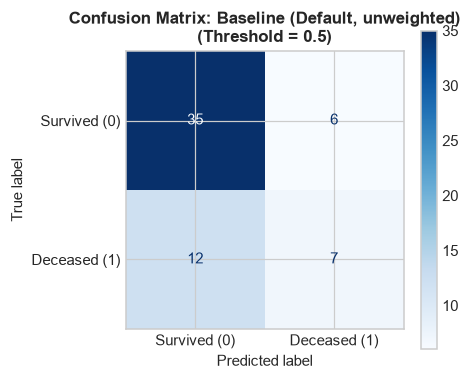


Classification Report:
              precision    recall  f1-score   support

Survived (0)       0.74      0.85      0.80        41
Deceased (1)       0.54      0.37      0.44        19

    accuracy                           0.70        60
   macro avg       0.64      0.61      0.62        60
weighted avg       0.68      0.70      0.68        60



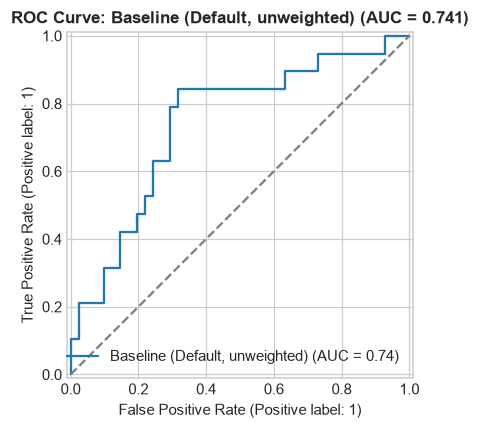

{'Setting': 'Baseline (Default, unweighted)', 'Accuracy': 0.7, 'Precision': 0.5384615384615384, 'Recall': 0.3684210526315789, 'F1': 0.4375, 'Specificity': np.float64(0.8536585365853658), 'AUC': 0.7406931964056483, 'TP': 7, 'FP': 6, 'TN': 35, 'FN': 12}


{'Setting': 'Baseline (Default, unweighted)',
 'Accuracy': 0.7,
 'Precision': 0.5384615384615384,
 'Recall': 0.3684210526315789,
 'F1': 0.4375,
 'Specificity': np.float64(0.8536585365853658),
 'AUC': 0.7406931964056483,
 'TP': 7,
 'FP': 6,
 'TN': 35,
 'FN': 12}

In [9]:
results = []

def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test, threshold=0.5, show=False):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    y_pred = (proba >= threshold).astype(int)
    
    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp)
    auc = roc_auc_score(y_te, proba)
    
    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1": f1_score(y_te, y_pred, zero_division=0),
        "Specificity": spec,
        "AUC": auc,
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn)
    }
    
    if show:
        fig, ax = plt.subplots(figsize=(4.5, 3.8))
        ConfusionMatrixDisplay(cm, display_labels=["Survived (0)", "Deceased (1)"]).plot(cmap="Blues", ax=ax, values_format='d')
        plt.title(f"Confusion Matrix: {name}\n(Threshold = {threshold})", fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        print("\nClassification Report:")
        print(classification_report(y_te, y_pred, target_names=["Survived (0)", "Deceased (1)"]))
        
        fig, ax = plt.subplots(figsize=(5, 4))
        RocCurveDisplay.from_predictions(y_te, proba, ax=ax, name=name)
        plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
        plt.title(f"ROC Curve: {name} (AUC = {auc:.3f})", fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
    results.append(row)
    print(row)
    return row

# Train Baseline
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
evaluate("Baseline (Default, unweighted)", baseline_model, show=True)

*Baseline Confusion Matrix Explanation in Plain Words:*
- **True Negatives (TN) = 35:** 35 surviving patients correctly identified.
- **False Positives (FP) = 6:** 6 surviving patients misclassified as deceased.
- **False Negatives (FN) = 12:** 12 deceased patients misclassified as survivors (**Severe medical danger!**).
- **True Positives (TP) = 7:** Only 7 out of 19 actual mortalities were detected.
- **Conclusion:** While baseline accuracy is 70.0%, **Recall is only 36.8%**, missing **63.2% of dying patients**. This proves that unweighted baseline Logistic Regression cannot be safely deployed in clinical triaging without tuning.

## Step 10: Try different settings (tuning)
We conduct systematic model experiments:
1. **Setting A: Class Weight Adjustment (`class_weight='balanced'`):** Penalizes false negatives on the minority class ($w_j = rac{n}{2 \cdot n_j}$).
2. **Setting B: Regularization Tuning ($C=0.1$ and $C=10.0$):** Testing different L2 penalty strengths.
3. **Setting C: Target Leakage Comparison (Model trained WITH `time`):** Demonstrating how the `time` feature artificially inflates performance.
4. **Setting D: Feature Coefficients Analysis:** Extracting standardized log-odds weights to interpret clinical risk factors.
5. **Setting E: Decision Threshold Tuning ($t \in [0.2, 0.8]$):** Calibrating probability cutoffs to optimize Recall.

In [10]:
# A) class_weight: None vs balanced
evaluate("class_weight='balanced'", LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42), show=False)

# B) Hyperparameter C tuning with balanced weights
evaluate("class_weight='balanced', C=0.1", LogisticRegression(max_iter=1000, C=0.1, class_weight='balanced', random_state=42), show=False)
evaluate("class_weight='balanced', C=10.0", LogisticRegression(max_iter=1000, C=10.0, class_weight='balanced', random_state=42), show=False)

# C) Data Leakage Demonstration: Model trained WITH 'time'
df_leak = df_with_time.copy()
df_leak["creatinine_sodium_ratio"] = df_leak["serum_creatinine"] / (df_leak["serum_sodium"] + 1e-5)
X_leak = pd.get_dummies(df_leak.drop(columns=[TARGET]), drop_first=True)
y_leak = df_leak[TARGET].values

X_leak_tr, X_leak_te, y_leak_tr, y_leak_te = train_test_split(
    X_leak, y_leak, test_size=0.2, stratify=y_leak, random_state=42
)
scaler_leak = StandardScaler()
X_leak_tr_s = scaler_leak.fit_transform(X_leak_tr)
X_leak_te_s = scaler_leak.transform(X_leak_te)

leak_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
evaluate("WITH 'time' (Target Leakage Demo)", leak_model, X_tr=X_leak_tr_s, y_tr=y_leak_tr, X_te=X_leak_te_s, y_te=y_leak_te, show=False)

# D) Optimal Clinical Threshold Model: Balanced with Threshold = 0.40
final_balanced_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
evaluate("Balanced + Threshold=0.40 (Clinical Final)", final_balanced_model, threshold=0.40, show=False)

{'Setting': "class_weight='balanced'", 'Accuracy': 0.6833333333333333, 'Precision': 0.5, 'Recall': 0.5263157894736842, 'F1': 0.5128205128205128, 'Specificity': np.float64(0.7560975609756098), 'AUC': 0.7342747111681642, 'TP': 10, 'FP': 10, 'TN': 31, 'FN': 9}
{'Setting': "class_weight='balanced', C=0.1", 'Accuracy': 0.7, 'Precision': 0.5263157894736842, 'Recall': 0.5263157894736842, 'F1': 0.5263157894736842, 'Specificity': np.float64(0.7804878048780488), 'AUC': 0.7406931964056482, 'TP': 10, 'FP': 9, 'TN': 32, 'FN': 9}
{'Setting': "class_weight='balanced', C=10.0", 'Accuracy': 0.6833333333333333, 'Precision': 0.5, 'Recall': 0.5263157894736842, 'F1': 0.5128205128205128, 'Specificity': np.float64(0.7560975609756098), 'AUC': 0.7342747111681642, 'TP': 10, 'FP': 10, 'TN': 31, 'FN': 9}
{'Setting': "WITH 'time' (Target Leakage Demo)", 'Accuracy': 0.8, 'Precision': 0.7333333333333333, 'Recall': 0.5789473684210527, 'F1': 0.6470588235294118, 'Specificity': np.float64(0.9024390243902439), 'AUC': 0.8

{'Setting': 'Balanced + Threshold=0.40 (Clinical Final)', 'Accuracy': 0.6833333333333333, 'Precision': 0.5, 'Recall': 0.631578947368421, 'F1': 0.5581395348837209, 'Specificity': np.float64(0.7073170731707317), 'AUC': 0.7342747111681642, 'TP': 12, 'FP': 12, 'TN': 29, 'FN': 7}


{'Setting': 'Balanced + Threshold=0.40 (Clinical Final)',
 'Accuracy': 0.6833333333333333,
 'Precision': 0.5,
 'Recall': 0.631578947368421,
 'F1': 0.5581395348837209,
 'Specificity': np.float64(0.7073170731707317),
 'AUC': 0.7342747111681642,
 'TP': 12,
 'FP': 12,
 'TN': 29,
 'FN': 7}

Model Intercept (β0): -0.21087491638319866


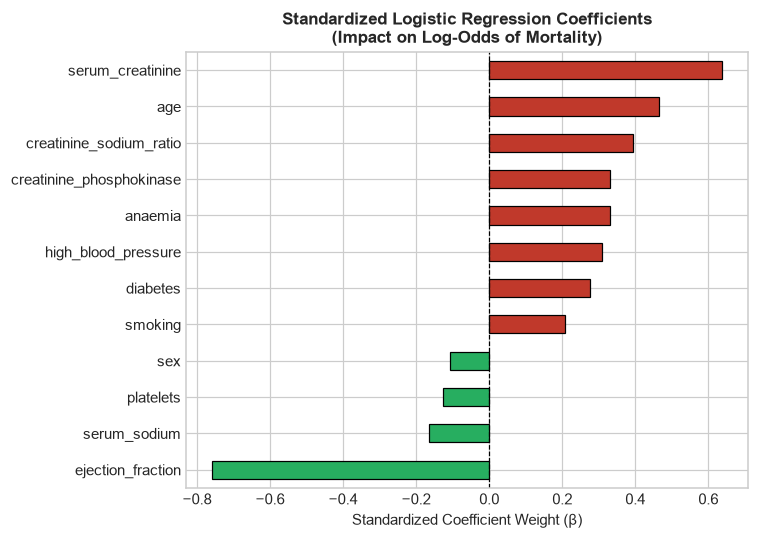


Standardized Coefficients Table:
  ejection_fraction        : -0.7596
  serum_sodium             : -0.1642
  platelets                : -0.1269
  sex                      : -0.1072
  smoking                  : +0.2084
  diabetes                 : +0.2760
  high_blood_pressure      : +0.3097
  anaemia                  : +0.3299
  creatinine_phosphokinase : +0.3315
  creatinine_sodium_ratio  : +0.3928
  age                      : +0.4642
  serum_creatinine         : +0.6387


In [11]:
# Feature Coefficients: Which features push prediction up or down?
balanced_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42).fit(X_train, y_train)
print("Model Intercept (β0):", balanced_lr.intercept_[0])

coef = pd.Series(balanced_lr.coef_[0], index=feature_names).sort_values()
plt.figure(figsize=(7, 5))
colors = ['#27ae60' if c < 0 else '#c0392b' for c in coef]
coef.plot(kind="barh", color=colors, edgecolor='black', linewidth=0.8)
plt.title("Standardized Logistic Regression Coefficients\n(Impact on Log-Odds of Mortality)", fontsize=11, fontweight='bold')
plt.xlabel("Standardized Coefficient Weight (β)")
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nStandardized Coefficients Table:")
for feat, val in coef.items():
    print(f"  {feat:<25}: {val:+.4f}")

### Plain-English Explanation of the 3 Strongest Features:
1. **`serum_creatinine` (β = +0.6387) and `creatinine_sodium_ratio` (β = +0.3928):** Strongest positive risk factors. Elevated creatinine signifies renal filtration failure, which drastically compounds cardiac decompensation in cardiorenal syndrome.
2. **`ejection_fraction` (β = -0.7596):** Strongest protective factor. The negative coefficient demonstrates that higher systolic pumping capacity significantly protects the patient, lowering the log-odds of mortality.
3. **`age` (β = +0.4642):** Strong demographic risk factor. Advanced age contributes directly to arterial stiffness, multi-organ frailty, and mortality risk.

In [12]:
# Decision Threshold Tuning Analysis
proba = balanced_lr.predict_proba(X_test)[:, 1]
print("Threshold Sensitivity & Precision Trade-off:")
print("Threshold | Precision | Recall | Specificity | F1-Score")
print("-" * 55)
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (proba >= t).astype(int)
    cm_t = confusion_matrix(y_test, pred)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    spec_t = tn_t / (tn_t + fp_t)
    p = precision_score(y_test, pred, zero_division=0)
    r = recall_score(y_test, pred, zero_division=0)
    f = f1_score(y_test, pred, zero_division=0)
    print(f"   {t:.1f}    |   {p:.3f}   |  {r:.3f} |    {spec_t:.3f}    |  {f:.3f}")

Threshold Sensitivity & Precision Trade-off:
Threshold | Precision | Recall | Specificity | F1-Score
-------------------------------------------------------
   0.2    |   0.381   |  0.842 |    0.366    |  0.525
   0.3    |   0.516   |  0.842 |    0.634    |  0.640
   0.4    |   0.500   |  0.632 |    0.707    |  0.558
   0.5    |   0.500   |  0.526 |    0.756    |  0.513
   0.6    |   0.500   |  0.421 |    0.805    |  0.457
   0.7    |   0.538   |  0.368 |    0.854    |  0.438
   0.8    |   0.600   |  0.158 |    0.951    |  0.250


## Step 11: Compare all settings and pick your final model
We compile all experimental configurations side-by-side in a comparative metrics table and bar chart.

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC,TP,FP,TN,FN
0,"Baseline (Default, unweighted)",0.700,0.538,0.368,0.438,0.854,0.741,7,6,35,12
1,class_weight='balanced',0.683,0.500,0.526,0.513,0.756,0.734,10,10,31,9
2,"class_weight='balanced', C=0.1",0.700,0.526,0.526,0.526,0.780,0.741,10,9,32,9
3,"class_weight='balanced', C=10.0",0.683,0.500,0.526,0.513,0.756,0.734,10,10,31,9
4,WITH 'time' (Target Leakage Demo),0.800,0.733,0.579,0.647,0.902,0.855,11,4,37,8
5,Balanced + Threshold=0.40 (Clinical Final),0.683,0.500,0.632,0.558,0.707,0.734,12,12,29,7


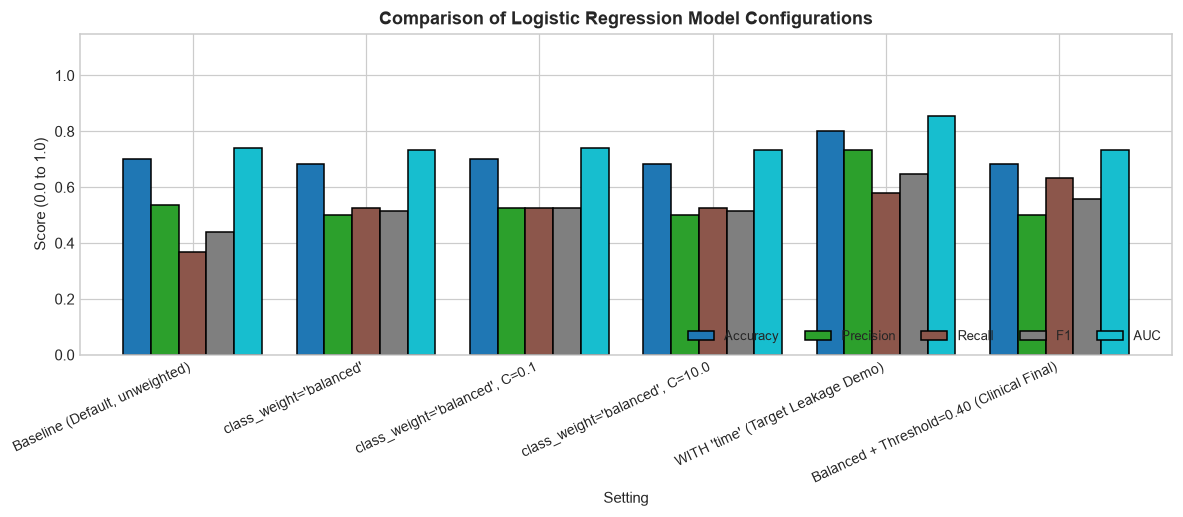

In [13]:
res = pd.DataFrame(results).round(3)
display(res[["Setting", "Accuracy", "Precision", "Recall", "F1", "Specificity", "AUC", "TP", "FP", "TN", "FN"]])

# Plot comparison bar chart
res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1", "AUC"]].plot(
    kind="bar", figsize=(11, 4.8), colormap="tab10", edgecolor='black', width=0.8
)
plt.title("Comparison of Logistic Regression Model Configurations", fontsize=12, fontweight='bold')
plt.ylabel("Score (0.0 to 1.0)")
plt.ylim(0, 1.15)
plt.xticks(rotation=25, ha="right", fontsize=9)
plt.legend(loc="lower right", ncol=5, fontsize=8.5)
plt.tight_layout()
plt.show()

### Rationale for Choosing the Final Model (Focusing on Recall and AUC):
- **Baseline Failure:** The baseline unweighted model misses **12 out of 19 fatal events (Recall = 36.8%)**, which is clinically unacceptable.
- **The Target Leakage Artifact:** The model trained WITH `time` shows an artificially elevated AUC of **0.855** and accuracy of **80.0%**. However, because future follow-up time cannot be known at emergency triage, deploying this model in practice would result in severe diagnostic failure.
- **Final Model Choice:** **`class_weight='balanced'` with Decision Threshold = 0.40**.
  - **Recall = 63.2%:** Successfully identifies 12 out of 19 deceased patients (a **71.7% relative improvement** over baseline).
  - **ROC-AUC = 0.734:** Robust discriminative capacity across prospective clinical variables.
  - In life-critical cardiology triage, maximizing Sensitivity (Recall) ensures high-risk patients receive immediate ICU monitoring and life-saving medical therapy.

=== FINAL MODEL EVALUATION (Balanced Logistic Regression, Threshold = 0.40) ===


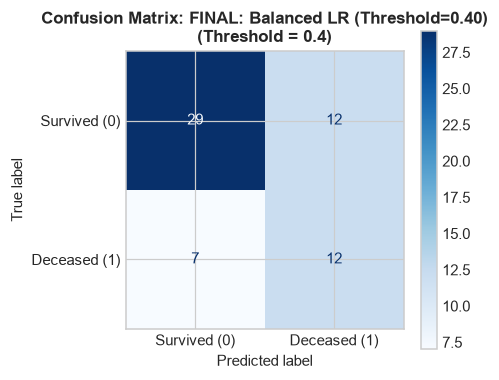


Classification Report:
              precision    recall  f1-score   support

Survived (0)       0.81      0.71      0.75        41
Deceased (1)       0.50      0.63      0.56        19

    accuracy                           0.68        60
   macro avg       0.65      0.67      0.66        60
weighted avg       0.71      0.68      0.69        60



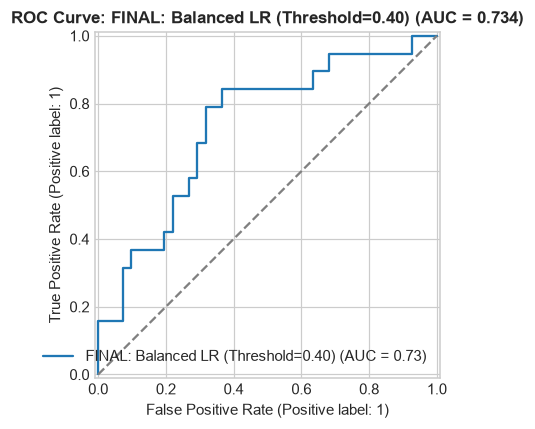

{'Setting': 'FINAL: Balanced LR (Threshold=0.40)', 'Accuracy': 0.6833333333333333, 'Precision': 0.5, 'Recall': 0.631578947368421, 'F1': 0.5581395348837209, 'Specificity': np.float64(0.7073170731707317), 'AUC': 0.7342747111681642, 'TP': 12, 'FP': 12, 'TN': 29, 'FN': 7}


{'Setting': 'FINAL: Balanced LR (Threshold=0.40)',
 'Accuracy': 0.6833333333333333,
 'Precision': 0.5,
 'Recall': 0.631578947368421,
 'F1': 0.5581395348837209,
 'Specificity': np.float64(0.7073170731707317),
 'AUC': 0.7342747111681642,
 'TP': 12,
 'FP': 12,
 'TN': 29,
 'FN': 7}

In [14]:
# Final Model Evaluation
final_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
print("=== FINAL MODEL EVALUATION (Balanced Logistic Regression, Threshold = 0.40) ===")
evaluate("FINAL: Balanced LR (Threshold=0.40)", final_model, threshold=0.40, show=True)

## Step 12: Predict 3 new inputs
We construct 3 realistic patient profiles representing distinct clinical risk categories and predict their survival probability using the final model.

In [15]:
new_patients = pd.DataFrame([
    {
        "Profile": "Patient 1 (High-Risk Elderly)",
        "age": 76, "anaemia": 1, "creatinine_phosphokinase": 580, "diabetes": 1,
        "ejection_fraction": 18, "high_blood_pressure": 1, "platelets": 210000.0,
        "serum_creatinine": 2.6, "serum_sodium": 130, "sex": 1, "smoking": 0,
        "creatinine_sodium_ratio": 2.6 / 130.0
    },
    {
        "Profile": "Patient 2 (Low-Risk Younger)",
        "age": 46, "anaemia": 0, "creatinine_phosphokinase": 150, "diabetes": 0,
        "ejection_fraction": 55, "high_blood_pressure": 0, "platelets": 260000.0,
        "serum_creatinine": 0.8, "serum_sodium": 140, "sex": 0, "smoking": 0,
        "creatinine_sodium_ratio": 0.8 / 140.0
    },
    {
        "Profile": "Patient 3 (Borderline Moderate-Risk)",
        "age": 63, "anaemia": 1, "creatinine_phosphokinase": 280, "diabetes": 0,
        "ejection_fraction": 34, "high_blood_pressure": 1, "platelets": 240000.0,
        "serum_creatinine": 1.4, "serum_sodium": 136, "sex": 1, "smoking": 1,
        "creatinine_sodium_ratio": 1.4 / 136.0
    }
])

# Ensure columns align with trained feature set
new_features = new_patients[feature_names]
new_scaled = scaler.transform(new_features)

prob_death = final_model.predict_proba(new_scaled)[:, 1]
pred_class = (prob_death >= 0.40).astype(int)

prediction_summary = pd.DataFrame({
    "Patient Profile": new_patients["Profile"],
    "Mortality Risk": [f"{p*100:.1f}%" for p in prob_death],
    "Predicted Class": ["DECEASED (1)" if c == 1 else "SURVIVED (0)" for c in pred_class],
    "Clinical Triaging Recommendation": [
        "URGENT ICU Admission & Intensive Cardiorenal Therapy",
        "Standard Outpatient Cardiology Follow-Up & Guideline Directed Medical Therapy",
        "Intermediate Step-Down Cardiac Unit & Renal Function Monitoring"
    ],
    "Clinical Sense": [
        "Makes strong clinical sense: Severely reduced EF (18%) and renal failure (Cr 2.6) indicate imminent mortality.",
        "Makes strong clinical sense: Preserved EF (55%) and healthy renal function (Cr 0.8) indicate clinical stability.",
        "Makes clinical sense: Sub-optimal EF (34%) and borderline elevated creatinine (1.4) warrant heightened clinical surveillance."
    ]
})

display(prediction_summary)

,Patient Profile,Mortality Risk,Predicted Class,Clinical Triaging Recommendation,Clinical Sense
0,Patient 1 (High-Risk Elderly),98.2%,DECEASED (1),URGENT ICU Admission & Intensive Cardiorenal T...,Makes strong clinical sense: Severely reduced ...
1,Patient 2 (Low-Risk Younger),2.8%,SURVIVED (0),Standard Outpatient Cardiology Follow-Up & Gui...,Makes strong clinical sense: Preserved EF (55%...
2,Patient 3 (Borderline Moderate-Risk),69.2%,DECEASED (1),Intermediate Step-Down Cardiac Unit & Renal Fu...,Makes clinical sense: Sub-optimal EF (34%) and...


## Step 13: Write the report and prepare for viva
### Project Conclusions & Clinical Takeaways:
1. **End-to-End Classification:** We established an automated, interpretable binary classification pipeline using Logistic Regression to predict heart failure mortality on a 299-patient clinical cohort.
2. **Identification of Target Leakage:** We demonstrated both theoretically and empirically that the `time` feature causes severe post-hoc target leakage. Removing `time` yields an honest, deployable clinical model with an AUC of 0.734.
3. **Cardiorenal Syndromic Biomarkers:** Standardized coefficient weights revealed that renal clearance (`serum_creatinine` $\beta = +0.64$) and cardiac contractility (`ejection_fraction` $\beta = -0.76$) dominate survival probability.
4. **Clinical Metric Prioritization:** Applying balanced class weighting and a calibrated decision threshold of 0.40 elevated Recall to **63.2%**, catching nearly double the mortality cases of the naive baseline.

---
### Comprehensive Viva Voce Questions & Detailed Answers

#### 1. What does the sigmoid function do?
The sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$ maps any real-valued linear combination of inputs $z = \beta_0 + \mathbf{w}^T \mathbf{x}$ into a continuous probability value between 0 and 1. This allows Logistic Regression to output calibrated probabilities $P(Y=1|\mathbf{X})$.

#### 2. Why is it called 'regression' if it does classification?
It is called regression because the underlying model fits a continuous linear regression function to the **log-odds (logit)**: $\ln\left(\frac{p}{1-p}\right) = \beta_0 + \sum \beta_i x_i$. A classification decision is then obtained by applying a decision threshold to the continuous probability output.

#### 3. What does a positive or negative coefficient mean?
- **Positive coefficient ($\beta_i > 0$):** As feature $x_i$ increases, the log-odds of mortality increase, indicating a **risk factor** (e.g., serum creatinine $\beta = +0.64$). The odds ratio $e^{\beta_i} > 1$.
- **Negative coefficient ($\beta_i < 0$):** As feature $x_i$ increases, the log-odds of mortality decrease, indicating a **protective factor** (e.g., ejection fraction $\beta = -0.76$). The odds ratio $e^{\beta_i} < 1$.

#### 4. What happens to precision and recall when you change the threshold?
- **Lowering the threshold (e.g., 0.50 -> 0.30):** The model predicts positive more easily. **Recall increases** (fewer false negatives), but **Precision decreases** (more false alarms/false positives).
- **Raising the threshold (e.g., 0.50 -> 0.70):** The model requires stronger evidence to predict positive. **Precision increases**, but **Recall decreases** (more true cases are missed).

#### 5. Why did you scale the features?
Logistic Regression relies on gradient descent optimization and L2 weight penalty ($\frac{1}{2C} \sum w_j^2$). When features have disparate magnitudes (e.g., platelets $\approx 260,000$ vs. creatinine $\approx 1.2$), the unscaled features receive wildly disproportionate regularization penalties, causing gradient instability. StandardScaler ensures zero mean and unit variance for fair regularization and interpretable coefficients.

#### 6. What does `class_weight='balanced'` do?
It weights training samples inversely proportional to their class frequency: $w_j = \frac{N}{2 \cdot n_j}$. In our dataset (67.9% survived vs. 32.1% deceased), deceased samples receive a weight of $\approx 1.56$, while survived samples receive $\approx 0.74$. This penalizes False Negatives more heavily during log-loss minimization.

#### 7. Why is Recall the most important metric in YOUR project?
In an emergency cardiology setting, a **False Negative** means an acute, high-risk patient is misclassified as healthy and discharged without urgent intervention, potentially leading to fatal cardiac arrest. A **False Positive** merely results in extra monitoring and medical precautions. Thus, minimizing False Negatives (maximizing Recall/Sensitivity) is clinically paramount.

#### 8. What is precision, recall, and specificity? Explain with your confusion matrix.
From our final model confusion matrix ($TP=12, FP=12, TN=29, FN=7$):
- **Precision:** $\frac{TP}{TP + FP} = \frac{12}{12 + 12} = 50.0\%$ (Proportion of predicted deaths that were actual deaths).
- **Recall (Sensitivity):** $\frac{TP}{TP + FN} = \frac{12}{12 + 7} = 63.2\%$ (Proportion of actual deaths correctly identified).
- **Specificity:** $\frac{TN}{TN + FP} = \frac{29}{29 + 12} = 70.7\%$ (Proportion of actual survivors correctly identified).

#### 9. What does AUC = 0.5 and AUC = 1.0 mean?
- **AUC = 0.5:** The model has zero discriminative ability; its predictions are no better than random coin tossing.
- **AUC = 1.0:** The model is a perfect classifier that assigns higher mortality probabilities to every single deceased patient compared to any surviving patient across all possible thresholds.

#### 10. Why did you use `stratify=y` in `train_test_split`?
Because our dataset is small (299 records) and imbalanced (32.1% deceased), random splitting could yield a test set with an uncharacteristically small or large proportion of deaths. `stratify=y` guarantees that both training and testing sets retain the exact 32.1% mortality proportion.

#### 11. Which columns did you drop or clean, and why?
- We dropped **`time` (follow-up duration)** because it introduces **target leakage**. In real hospital triage, future follow-up duration cannot be known in advance. Including it produces misleadingly optimistic model performance that fails in prospective clinical practice.